# Яндекс Книги и BitMotion Kit

**Автор · Шалак Лидия**

Два исследования на пользовательских данных. В первом сравниваю среднее время чтения и прослушивания в Москве и Санкт-Петербурге. Во втором оцениваю, повысил ли новый интерфейс интернет-магазина конверсию из регистрации в покупку.

## Данные и запуск

Учебные выгрузки предоставлены Яндекс Практикумом.

| Набор данных | Что содержит | Источник |
|---|---|---|
| Яндекс Книги | Город, `puid` пользователя и суммарные часы активности `hours` | [CSV](https://code.s3.yandex.net/datasets/yandex_knigi_data.csv) |
| Участники BitMotion Kit | `user_id`, группа, эксперимент и устройство | [CSV](https://code.s3.yandex.net/datasets/ab_test_participants.csv) |
| Журнал BitMotion Kit | `user_id`, время и тип события, дополнительные детали | [ZIP](https://code.s3.yandex.net/datasets/ab_test_events.zip) |

Для запуска нужны Python 3, Jupyter Notebook, pandas, NumPy, Matplotlib и SciPy. Выполните ячейки по порядку. Ноутбук ищет файлы рядом с собой и в каталогах `datasets/` и `../datasets/`, затем загружает их по ссылкам выше. Для загрузки из другой локальной папки задайте переменную окружения `YANDEX_BOOKS_DATA_DIR`.

In [1]:
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

ALPHA = 0.05
DATA_URL = 'https://code.s3.yandex.net/datasets/'
DATA_DIR = os.environ.get('YANDEX_BOOKS_DATA_DIR')


def dataset_source(filename):
    if DATA_DIR:
        return Path(DATA_DIR).expanduser() / filename

    for folder in (Path('datasets'), Path('../datasets'), Path('.')):
        path = folder / filename
        if path.is_file():
            return path

    return DATA_URL + filename

## 1. Активность пользователей Яндекс Книг

### Загрузка и проверка данных

Сравниваю суммарное время чтения и прослушивания на пользователя с 1 сентября по 11 декабря 2024 года. Первый столбец CSV — технический индекс строки. Для сравнения формирую непересекающиеся группы и исключаю пользователей, представленных в обоих городах.

In [2]:
books = pd.read_csv(dataset_source('yandex_knigi_data.csv'), index_col=0)
display(books.head())
print(f'Строк: {len(books):,}')
display(books.isna().sum().rename('пропуски'))

city_count = books.groupby('puid')['city'].nunique()
shared_ids = city_count[city_count.gt(1)].index

print('Дополнительные строки с повторяющимся puid:', books['puid'].duplicated().sum())
print('Повторы пары город — puid:', books.duplicated(['city', 'puid']).sum())
print('Пользователи с записями в обоих городах:', len(shared_ids))

independent = books.loc[~books['puid'].isin(shared_ids)].copy()
for label, frame in [('До фильтрации', books), ('После фильтрации', independent)]:
    print(label)
    display(frame.groupby('city')['hours'].describe().round(3))

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


Строк: 8,784


city     0
puid     0
hours    0
Name: пропуски, dtype: int64

Дополнительные строки с повторяющимся puid: 244
Повторы пары город — puid: 0
Пользователи с записями в обоих городах: 244
До фильтрации


,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Москва,6234.0,10.881,36.852,0.0,0.06,0.924,5.940,857.209
Санкт-Петербург,2550.0,11.593,39.705,0.0,0.08,0.985,6.509,978.765


После фильтрации


,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Москва,5990.0,10.848,36.926,0.0,0.057,0.888,5.933,857.209
Санкт-Петербург,2306.0,11.264,39.832,0.0,0.060,0.875,6.138,978.765


### Распределение активности

В обеих выборках медиана близка к 0,9 часа, а среднее превышает 10 часов. У небольшой доли пользователей активность достигает сотен часов. Гистограмма с преобразованием `log1p` и накопленные доли помогают сравнить распределения при таком разбросе. Для теста использую часы в исходной шкале.

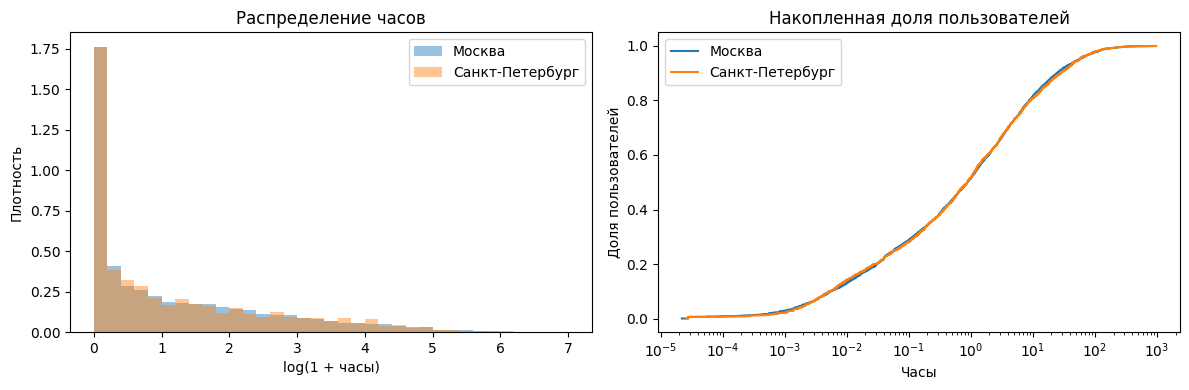

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for city, group in independent.groupby('city'):
    hours = group['hours']
    axes[0].hist(np.log1p(hours), bins=np.linspace(0, 7, 36),
                 density=True, alpha=0.45, label=city)
    sorted_hours = np.sort(hours)
    axes[1].step(sorted_hours, np.arange(1, len(hours) + 1) / len(hours),
                 where='post', label=city)
axes[0].set(xlabel='log(1 + часы)', ylabel='Плотность', title='Распределение часов')
axes[1].set(xlabel='Часы', ylabel='Доля пользователей', xscale='log',
            title='Накопленная доля пользователей')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

### Проверка гипотезы

Проверяю, выше ли среднее время активности в Санкт-Петербурге. Нулевая гипотеза — среднее в Санкт-Петербурге меньше или равно московскому. Альтернативная гипотеза — среднее в Санкт-Петербурге выше.

Использую односторонний t-тест Уэлча при уровне значимости 0,05. Он сравнивает средние двух независимых выборок и допускает разные дисперсии.

In [4]:
spb = independent.loc[independent['city'].eq('Санкт-Петербург'), 'hours']
moscow = independent.loc[independent['city'].eq('Москва'), 'hours']

welch = stats.ttest_ind(spb, moscow, equal_var=False, alternative='greater')

print(f'Разница средних СПб − Москва: {spb.mean() - moscow.mean():.4f} ч')
print(f't = {welch.statistic:.4f}, p-value = {welch.pvalue:.6f}')

Разница средних СПб − Москва: 0.4162 ч
t = 0.4350, p-value = 0.331796


### Результат сравнения городов

После исключения 244 общих пользователей в выборках осталось 5 990 пользователей Москвы и 2 306 пользователей Санкт-Петербурга. Средние составили 10,85 и 11,26 часа соответственно. Разница в выборках — 0,42 часа, p-value — 0,3318. При уровне значимости 0,05 данных недостаточно, чтобы сделать вывод о более высоком среднем в Санкт-Петербурге. Вывод относится к пользователям, представленным в выгрузке только в одном из городов.

## 2. A/B-тест интерфейса BitMotion Kit

### Цель и метрика

Проверяю, увеличил ли новый интерфейс долю зарегистрированных пользователей, совершивших хотя бы одну покупку в течение первых семи суток после регистрации. Группа A использовала старый интерфейс, группа B — новый. Целевой прирост составляет **3 процентных пункта**.

In [5]:
participants = pd.read_csv(
    dataset_source('ab_test_participants.csv'), dtype={'user_id': 'string'}
)
events = pd.read_csv(
    dataset_source('ab_test_events.zip'),
    dtype={'user_id': 'string'},
    parse_dates=['event_dt'],
    low_memory=False,
)

for label, frame in [('Участники', participants), ('События', events)]:
    print(f'{label}: {len(frame):,} строк, точных дублей: {frame.duplicated().sum():,}')
    display(frame.head(3))
    display(frame.isna().sum().rename('пропуски'))

print(f'Период журнала: {events["event_dt"].min()} — {events["event_dt"].max()}')
display(events['event_name'].value_counts().rename('события'))

Участники: 14,525 строк, точных дублей: 0


,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android


user_id    0
group      0
ab_test    0
device     0
Name: пропуски, dtype: int64

События: 787,286 строк, точных дублей: 36,318


,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN


user_id            0
event_dt           0
event_name         0
details       538264
Name: пропуски, dtype: int64

Период журнала: 2020-12-01 00:00:00 — 2020-12-31 23:59:48


event_name
login                                 248285
product_page                          195606
registration                          144183
purchase                              104836
product_cart                           94373
End of Black Friday Ads Campaign           1
Start of Christmas&New Year Promo          1
Start of CIS New Year Gift Lottery         1
Name: события, dtype: int64

### Состав групп и пересечение экспериментов

Выделяю участников `interface_eu_test`, проверяю уникальность назначения, состав устройств и участие в параллельном тесте. Плановая пропорция в доступных данных не указана, поэтому для проверки баланса использую допущение 50:50.

In [6]:
in_test = participants['ab_test'] == 'interface_eu_test'
trial = participants.loc[in_test].copy()

assert set(trial['group']) == {'A', 'B'}
assert trial['user_id'].notna().all() and trial['user_id'].is_unique

other_ids = participants.loc[~in_test, 'user_id']
trial['parallel'] = trial['user_id'].isin(other_ids)

groups = trial.groupby('group')['parallel'].agg(
    assigned='size', overlap='sum', share='mean',
)
display(groups)

# В ТЗ пропорция не указана, поэтому для проверки предполагаем 50:50.
p_value = stats.chisquare(groups['assigned']).pvalue
print(f'Проверка против 50:50: p-value = {p_value:.4f}')

display(pd.crosstab(trial['group'], trial['device'], normalize='index').round(4))

,assigned,overlap,share
group,,,
A,5383,431,0.080067
B,5467,456,0.083410


Проверка против 50:50: p-value = 0.4200


device,Android,Mac,PC,iPhone
group,,,,
A,0.4542,0.1051,0.2500,0.1906
B,0.4416,0.1013,0.2594,0.1977


### Семидневное окно и календарные события

Использую первую запись о регистрации. Оставляю участников, для которых журнал покрывает семь полных суток, и учитываю события с момента регистрации до истечения седьмых суток. Точные дубли удаляю после отбора событий нужного эксперимента. Праздничную акцию проверяю по дате её начала в журнале.

In [7]:
trial_events = events[events['user_id'].isin(trial['user_id'])]
print('Точных повторов среди событий теста:', trial_events.duplicated().sum())
trial_events = trial_events.drop_duplicates()

# Среди строк GLOBAL календарные события отмечены кодом ZONE_CODE.
global_events = events[events['user_id'] == 'GLOBAL']
calendar_events = global_events[global_events['details'].str.startswith('ZONE_CODE', na=False)]
display(calendar_events[['event_dt', 'event_name', 'details']])

Точных повторов среди событий теста: 6170


,event_dt,event_name,details
0,2020-12-01,End of Black Friday Ads Campaign,ZONE_CODE15
683503,2020-12-25,Start of Christmas&New Year Promo,ZONE_CODE09
773846,2020-12-30,Start of CIS New Year Gift Lottery,ZONE_CODE02


In [8]:
registrations = trial_events[trial_events['event_name'] == 'registration']
registration_counts = registrations['user_id'].value_counts()
print('ID с несколькими записями регистрации:', (registration_counts > 1).sum())

first_registration = registrations.groupby('user_id')['event_dt'].min().rename('registered_at')
users = trial.merge(first_registration, on='user_id', how='left', validate='one_to_one')

horizon = pd.Timedelta(days=7)
registration_cutoff = events['event_dt'].max() - horizon
users['full_window'] = users['registered_at'] <= registration_cutoff

display(users.groupby('group').agg(
    assigned=('user_id', 'size'),
    registered=('registered_at', 'count'),
    full_window=('full_window', 'sum'),
    first_registration=('registered_at', 'min'),
    last_registration=('registered_at', 'max'),
))

eligible = users[users['full_window']].copy()
timed = trial_events.merge(
    eligible[['user_id', 'registered_at']], on='user_id', validate='many_to_one',
)
timed['lifetime'] = timed['event_dt'] - timed['registered_at']

# От момента регистрации до истечения семи суток.
in_window = (timed['lifetime'] >= pd.Timedelta(0)) & (timed['lifetime'] < horizon)
window_events = timed[in_window]
print('Событий за первые семь суток:', len(window_events))

promo_start = calendar_events.loc[
    calendar_events['event_name'].eq('Start of Christmas&New Year Promo'), 'event_dt'
].item()
registered_at = eligible['registered_at']
window_includes_promo_start = registered_at.le(promo_start) & (
    (registered_at + horizon).gt(promo_start)
)
promo_overlap = (
    eligible.assign(window_includes_promo_start=window_includes_promo_start)
    .groupby('group')['window_includes_promo_start']
    .sum()
    .rename('начало акции попало в окно')
)
display(promo_overlap)

ID с несколькими записями регистрации: 0


,assigned,registered,full_window,first_registration,last_registration
group,,,,,
A,5383,5383,5383,2020-12-06 14:10:01,2020-12-23 23:50:29
B,5467,5467,5467,2020-12-06 17:20:22,2020-12-24 21:57:10


Событий за первые семь суток: 63449


group
A    2075
B    2003
Name: начало акции попало в окно, dtype: int64

### Размер выборки

При базовой конверсии 30%, минимальном обнаруживаемом приросте 3 п. п., уровне значимости 0,05 и мощности 80% рассчитываю размер каждой группы для одностороннего теста. Этот расчёт отвечает на вопрос, сколько участников нужно, чтобы обнаружить рост заданной величины.

In [9]:
baseline = 0.30
target_lift = 0.03
power = 0.80

target = baseline + target_lift
average_rate = (baseline + target) / 2
null_sd = math.sqrt(2 * average_rate * (1 - average_rate))
alt_sd = math.sqrt(baseline * (1 - baseline) + target * (1 - target))

# Размер одной группы для односторонней проверки роста конверсии.
z_alpha = stats.norm.ppf(1 - ALPHA)
z_power = stats.norm.ppf(power)
required_per_group = math.ceil(((z_alpha * null_sd + z_power * alt_sd) / target_lift) ** 2)

print('Нужно участников на группу:', required_per_group)
display(eligible.groupby('group').size().rename('фактически'))

Нужно участников на группу: 2964


group
A    5383
B    5467
Name: фактически, dtype: int64

### Конверсия и проверка роста

Засчитываю каждому участнику максимум одну покупку. Пользователи без покупки остаются в знаменателе. Повторяю расчёт без участников параллельного эксперимента, чтобы оценить, насколько меняется результат.

In [10]:
buyer_ids = window_events.loc[window_events['event_name'] == 'purchase', 'user_id']
eligible['bought'] = eligible['user_id'].isin(buyer_ids)

def conversion_table(users):
    return users.groupby('group')['bought'].agg(
        registered='size',
        buyers='sum',
        conversion='mean',
    ).reindex(['A', 'B'])

primary = conversion_table(eligible)
no_parallel = conversion_table(eligible[~eligible['parallel']])

print('Все подходящие участники')
display(primary)
print('Без участников параллельного теста')
display(no_parallel)

Все подходящие участники


,registered,buyers,conversion
group,,,
A,5383,1480,0.274940
B,5467,1600,0.292665


Без участников параллельного теста


,registered,buyers,conversion
group,,,
A,4952,1377,0.278069
B,5011,1480,0.295350


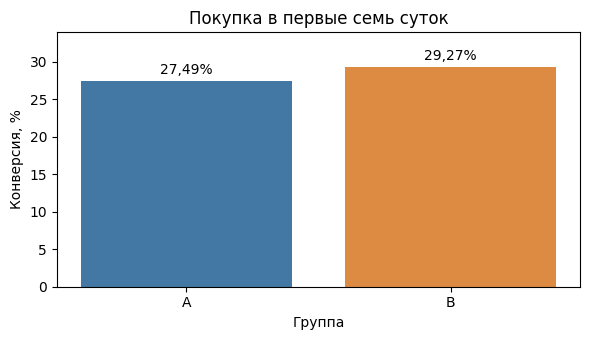

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.5))
rates_pct = primary['conversion'] * 100
bars = ax.bar(rates_pct.index, rates_pct, color=['#4378a5', '#dd8b43'])
labels = [f'{rate:.2f}%'.replace('.', ',') for rate in rates_pct]
ax.bar_label(bars, labels=labels, padding=3)
ax.set(xlabel='Группа', ylabel='Конверсия, %', title='Покупка в первые семь суток')
ax.set_ylim(0, rates_pct.max() * 1.16)
fig.tight_layout()
plt.show()

Односторонний Z-тест двух долей проверяет рост относительно нуля при уровне значимости 0,05. Для оценки величины эффекта рассчитываю двусторонний 95%-й доверительный интервал Уолда. Для проверки цели в 3 п. п. использую одностороннюю 95%-ю нижнюю границу эффекта.

In [12]:
# H₀: p_B ≤ p_A. H₁: p_B > p_A. Уровень значимости 0,05.
def assess_conversion(summary):
    group_sizes = summary['registered']
    rates = summary['conversion']
    delta = rates['B'] - rates['A']

    # Для Z-теста используем общую конверсию двух групп.
    pooled = summary['buyers'].sum(skipna=False) / group_sizes.sum(skipna=False)
    se_null = math.sqrt(pooled * (1 - pooled) * (1 / group_sizes).sum(skipna=False))
    z = delta / se_null

    # Для интервала Уолда учитываем конверсию каждой группы отдельно.
    group_variances = rates * (1 - rates) / group_sizes
    se_effect = math.sqrt(group_variances.sum(skipna=False))
    margin = stats.norm.ppf(1 - ALPHA / 2) * se_effect
    lower = delta - stats.norm.ppf(1 - ALPHA) * se_effect

    return pd.Series({
        'эффект, п. п.': 100 * delta,
        'z': z,
        'p-value (рост)': stats.norm.sf(z),
        '95% ДИ, нижняя, п. п.': 100 * (delta - margin),
        '95% ДИ, верхняя, п. п.': 100 * (delta + margin),
        '95% односторонняя нижняя, п. п.': 100 * lower,
        'подтверждён порог 3 п. п.': lower >= target_lift,
    })


display(pd.DataFrame({
    'Основная выборка': assess_conversion(primary),
    'Без пересечения': assess_conversion(no_parallel),
}))

,Основная выборка,Без пересечения
"эффект, п. п.",1.772546,1.728076
z,2.047449,1.906965
p-value (рост),0.020307,0.028263
"95% ДИ, нижняя, п. п.",0.076315,-0.047513
"95% ДИ, верхняя, п. п.",3.468777,3.503666
"95% односторонняя нижняя, п. п.",0.349024,0.237955
подтверждён порог 3 п. п.,False,False


### Результаты и ограничения эксперимента

- **Рост конверсии.** В контрольной группе купили 1 480 из 5 383 участников (27,49%), в тестовой — 1 600 из 5 467 (29,27%). Оценка прироста составляет **1,77 п. п.**, двусторонний 95%-й доверительный интервал — от **0,08 до 3,47 п. п.** Односторонний Z-тест даёт основания говорить о росте (`p = 0,0203`).
- **Целевой эффект.** Односторонняя 95%-я нижняя граница составляет **0,35 п. п.** Для подтверждения целевого прироста она должна достигать 3 п. п. Достижение цели остаётся неподтверждённым.
- **Проверки эксперимента.** У всех 10 850 участников есть полное семидневное окно. Фактические размеры групп превышают расчётные 2 964 участника на группу. При допущении 50:50 заметного отклонения в размерах групп нет (`p = 0,420`).
- **Ограничения.** После исключения 887 участников параллельного эксперимента оценка прироста близка к основной (**1,73 п. п.**, `p = 0,0283`). Начало праздничной акции попало в окна 2 075 участников A и 2 003 участников B. По журналу можно установить пересечение по времени. Участие конкретных пользователей в акции, её отдельный вклад и регион аудитории остаются неизвестными.